# 03 - Outlier detection

Looks for extreme values with the IQR and z-score rules, then decides whether any rows should be removed before modelling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../Data/concrete_data.csv")

print("Shape before dropping duplicates:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Shape after dropping duplicates :", df.shape)

Shape before dropping duplicates: (1030, 9)
Duplicate rows: 25
Shape after dropping duplicates : (1005, 9)


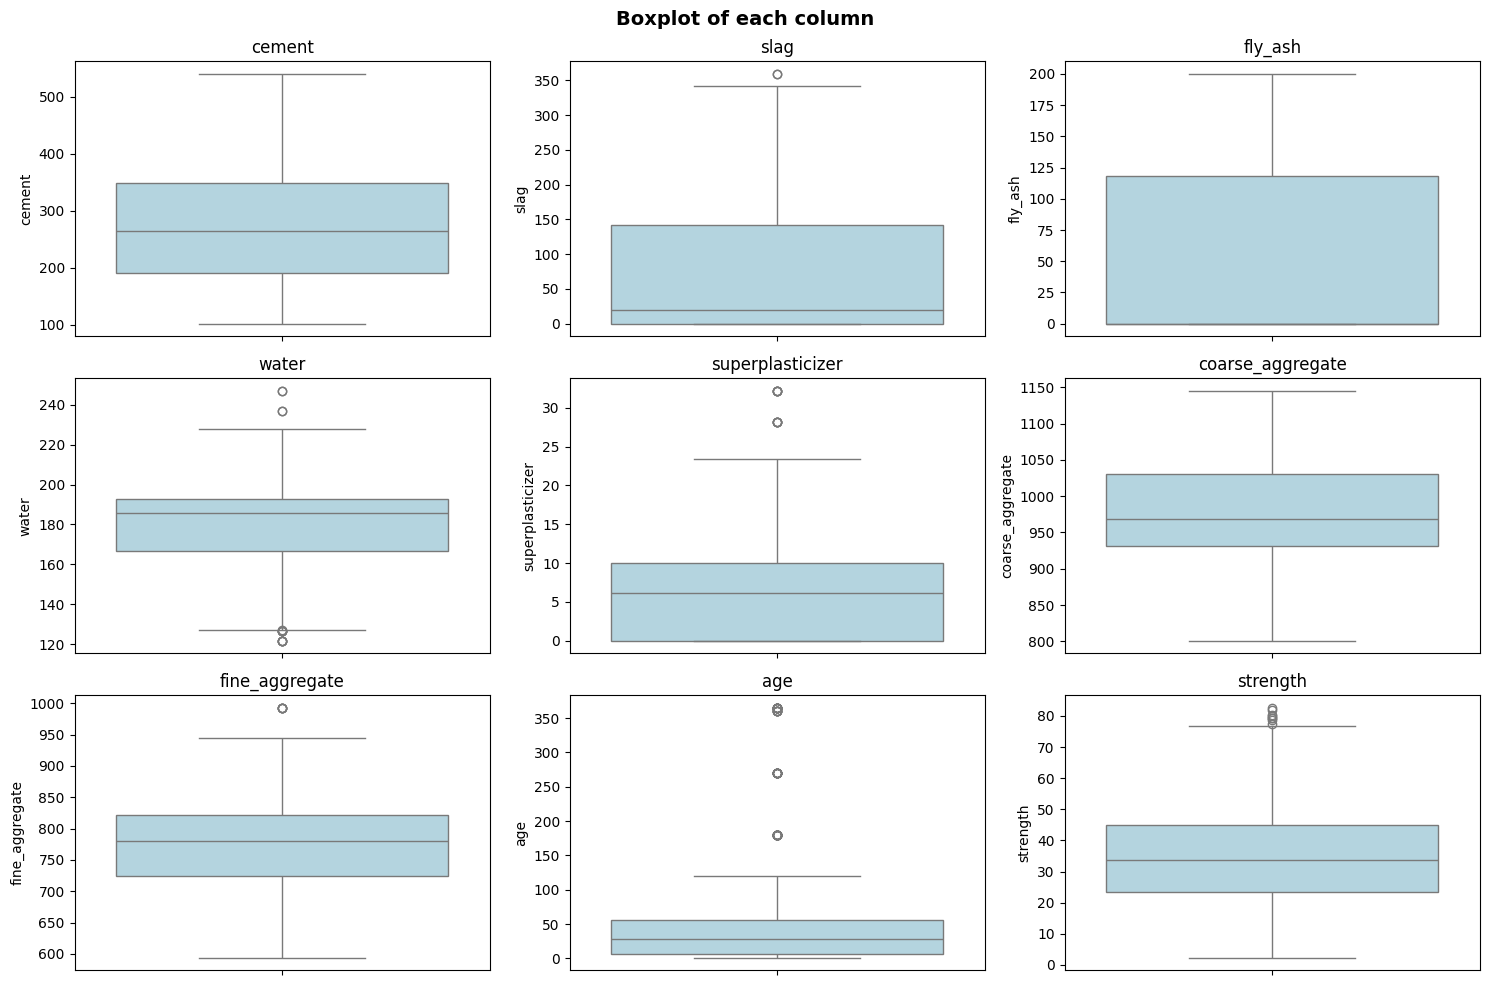

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    sns.boxplot(y=df[col], ax=axes[i], color="lightblue")
    axes[i].set_title(col)

plt.suptitle("Boxplot of each column", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [4]:
# True = this value is an outlier
iqr_outliers = pd.DataFrame(False, index=df.index, columns=df.columns)

for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    iqr_outliers[col] = (df[col] < lower) | (df[col] > upper)

print("IQR method (1.5 x IQR)")
print("-" * 30)
for col in df.columns:
    count = iqr_outliers[col].sum()
    if count > 0:
        print(col, ":", count)

IQR method (1.5 x IQR)
------------------------------
slag : 2
water : 15
superplasticizer : 10
fine_aggregate : 5
age : 59
strength : 8


In [5]:
# z-score = how many standard deviations a value is from the mean
z_outliers = pd.DataFrame(False, index=df.index, columns=df.columns)

for col in df.columns:
    z = (df[col] - df[col].mean()) / df[col].std()
    z_outliers[col] = z.abs() > 3

print("Z-score method (|z| > 3)")
print("-" * 30)
for col in df.columns:
    count = z_outliers[col].sum()
    if count > 0:
        print(col, ":", count)

Z-score method (|z| > 3)
------------------------------
slag : 4
water : 2
superplasticizer : 10
age : 33


In [6]:
print("IQR method")
print("  Total outlier values    :", iqr_outliers.sum().sum())
print("  Total rows with outliers:", iqr_outliers.any(axis=1).sum())
print()
print("Z-score method")
print("  Total outlier values    :", z_outliers.sum().sum())
print("  Total rows with outliers:", z_outliers.any(axis=1).sum())
print()

# Side-by-side comparison per column
comparison = pd.DataFrame({"IQR": iqr_outliers.sum(), "Z-score": z_outliers.sum()})
comparison

IQR method
  Total outlier values    : 99
  Total rows with outliers: 94

Z-score method
  Total outlier values    : 49
  Total rows with outliers: 49



,IQR,Z-score
cement,0,0
slag,2,4
fly_ash,0,0
water,15,2
superplasticizer,10,10
coarse_aggregate,0,0
fine_aggregate,5,0
age,59,33
strength,8,0


In [7]:
# Check every column except age (long-term age tests are real data)
cols_to_check = df.columns.drop("age")

# A row is removed if ANY of the checked columns has |z| > 3
rows_to_remove = z_outliers[cols_to_check].any(axis=1)

print("Rows flagged (z-score, excluding age):", rows_to_remove.sum())
df[rows_to_remove]

Rows flagged (z-score, excluding age): 16


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
76,469.0,117.2,0.0,137.8,32.2,852.1,840.5,3,40.196451
78,531.3,0.0,0.0,141.8,28.2,852.1,893.7,3,41.299612
94,469.0,117.2,0.0,137.8,32.2,852.1,840.5,7,54.896079
96,531.3,0.0,0.0,141.8,28.2,852.1,893.7,7,46.898158
113,469.0,117.2,0.0,137.8,32.2,852.1,840.5,28,66.899856
115,531.3,0.0,0.0,141.8,28.2,852.1,893.7,28,56.399137
131,469.0,117.2,0.0,137.8,32.2,852.1,840.5,56,69.299233
133,531.3,0.0,0.0,141.8,28.2,852.1,893.7,56,58.798513
149,469.0,117.2,0.0,137.8,32.2,852.1,840.5,91,70.698869
151,531.3,0.0,0.0,141.8,28.2,852.1,893.7,91,59.198409


In [8]:
flagged = df[rows_to_remove].copy()
flagged["water_binder"] = flagged["water"] / (flagged["cement"] + flagged["slag"] + flagged["fly_ash"])
strength_z = ((df["strength"] - df["strength"].mean()) / df["strength"].std())[rows_to_remove]

print("Flagged rows               :", len(flagged))
print("Distinct mixes among them  :", flagged.drop(columns=["age", "strength"]).drop_duplicates().shape[0])
print("Largest |z| of their strength:", round(strength_z.abs().max(), 2), "(not an outlier in the target)")
print("Superplasticizer max, all rows    :", df["superplasticizer"].max())
print("Superplasticizer max, if removed  :", df.loc[~rows_to_remove, "superplasticizer"].max())
flagged[["cement", "slag", "water", "superplasticizer", "water_binder", "age", "strength"]].describe().round(2)

Flagged rows               : 16
Distinct mixes among them  : 6
Largest |z| of their strength: 2.18 (not an outlier in the target)
Superplasticizer max, all rows    : 32.2
Superplasticizer max, if removed  : 23.4


,cement,slag,water,superplasticizer,water_binder,age,strength
count,16.00,16.00,16.00,16.00,16.00,16.00,16.00
mean,400.66,135.79,164.67,19.62,0.31,31.00,46.77
std,135.10,137.34,37.89,14.31,0.12,28.72,16.02
min,228.00,0.00,137.80,0.00,0.24,3.00,21.92
25%,238.95,0.00,137.80,4.50,0.24,7.00,36.73
50%,469.00,117.20,141.80,28.20,0.27,28.00,44.10
75%,531.30,173.42,185.70,32.20,0.31,35.00,58.90
max,531.30,359.40,247.00,32.20,0.62,91.00,70.70


### Decision: keep every row

The 16 flagged rows are only 6 distinct mixes, tested at several ages, and they are **not errors**:
- most are high-performance mixes: very low water/binder (about 0.24-0.27) with a high superplasticizer dose. Concrete that dry needs that much superplasticizer, so the "extreme" values belong together;
- the others simply sit at the edge of the design space (the maximum slag, 359.4, and the maximum water, 247 kg/m³);
- none of them has an unusual strength (largest |z| of the target is about 2.2).

Removing them would:
- shrink the range the model has seen (and the app accepts), e.g. superplasticizer from 32.2 down to 23.4 kg/m³, so these valid mixes would become extrapolation;
- lower accuracy slightly: with grouped-by-mix cross-validation, LightGBM scored R² 0.903 on all 1005 rows versus 0.897 on the 989 rows left after removal.

So modelling (`04_DataSplit`, `05_Model`) uses all 1005 de-duplicated rows. Tree models are not sensitive to extreme input values anyway. Nothing is written to disk by this notebook.